[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 300 out of 300 | elapsed:    0.0s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 300 out of 300 | elapsed:    0.0s finished


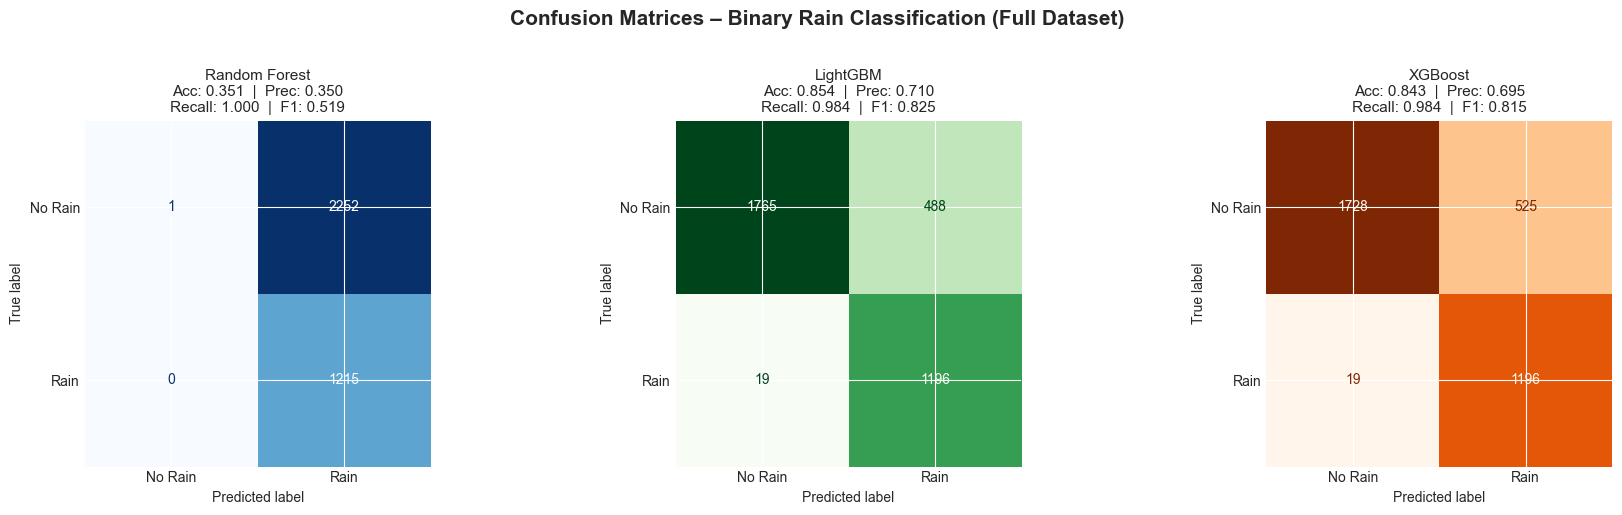

Plot saved as confusion_matrices.png

  Random Forest – Classification Report
              precision    recall  f1-score   support

     No Rain       1.00      0.00      0.00      2253
        Rain       0.35      1.00      0.52      1215

    accuracy                           0.35      3468
   macro avg       0.68      0.50      0.26      3468
weighted avg       0.77      0.35      0.18      3468


  LightGBM – Classification Report
              precision    recall  f1-score   support

     No Rain       0.99      0.78      0.87      2253
        Rain       0.71      0.98      0.83      1215

    accuracy                           0.85      3468
   macro avg       0.85      0.88      0.85      3468
weighted avg       0.89      0.85      0.86      3468


  XGBoost – Classification Report
              precision    recall  f1-score   support

     No Rain       0.99      0.77      0.86      2253
        Rain       0.69      0.98      0.81      1215

    accuracy                     

In [40]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# ============================================================================
# LOAD MODELS AND PREPROCESSING OBJECTS
# ============================================================================

rf_model      = joblib.load('random_forest_model.pkl')
lgbm_model    = joblib.load('lightgbm_model.pkl')
xgb_model     = joblib.load('xgboost_model.pkl')
scaler         = joblib.load('scaler.pkl')
selected_features = joblib.load('selected_features.pkl')

# ============================================================================
# REBUILD TEST SET (same logic as training notebook)
# ============================================================================

df = pd.read_csv('TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30 (1).csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# --- Feature engineering (must match notebook exactly) ---
df['temp_range']                  = df['tempmax'] - df['tempmin']
df['dew_point_depression']        = df['temp'] - df['dew']
df['humidity_deficit']            = 100 - df['humidity']
df['temp_dew_ratio']              = df['temp'] / (df['dew'] + 0.01)
df['pressure_trend']              = df['sealevelpressure'].diff(1)
df['pressure_trend_3']            = df['sealevelpressure'].diff(3)
df['pressure_acceleration']       = df['pressure_trend'].diff(1)
df['wind_power']                  = df['windspeed'] ** 3
df['wind_gust_ratio']             = df['windgust'] / (df['windspeed'] + 0.01)
df['wind_energy']                 = 0.5 * df['windspeed'] ** 2
df['cloud_cover_ratio']           = df['cloudcover'] / 100
df['solar_efficiency']            = df['solarenergy'] / (df['solarradiation'] + 0.01)
df['uv_radiation_ratio']          = df['uvindex'] / (df['solarradiation'] + 0.01)
df['month']                       = df['datetime'].dt.month
df['dayofyear']                   = df['datetime'].dt.dayofyear
df['month_sin']                   = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos']                   = np.cos(2 * np.pi * df['month'] / 12)
df['day_sin']                     = np.sin(2 * np.pi * df['dayofyear'] / 365)
df['day_cos']                     = np.cos(2 * np.pi * df['dayofyear'] / 365)
df['temp_humidity_interaction']   = df['temp'] * df['humidity']
df['pressure_cloud_interaction']  = df['sealevelpressure'] * df['cloudcover']
df['wind_cloud_interaction']      = df['windspeed'] * df['cloudcover']

for lag in [1, 2, 3, 7, 14]:
    df[f'precip_lag_{lag}']   = df['precipitation'].shift(lag)
    df[f'temp_lag_{lag}']     = df['temp'].shift(lag)
    df[f'humidity_lag_{lag}'] = df['humidity'].shift(lag)
    df[f'pressure_lag_{lag}'] = df['sealevelpressure'].shift(lag)
    df[f'cloud_lag_{lag}']    = df['cloudcover'].shift(lag)
    df[f'wind_lag_{lag}']     = df['windspeed'].shift(lag)

for window in [3, 7, 14]:
    df[f'temp_roll_mean_{window}']     = df['temp'].rolling(window, min_periods=1).mean()
    df[f'temp_roll_std_{window}']      = df['temp'].rolling(window, min_periods=1).std()
    df[f'humidity_roll_mean_{window}'] = df['humidity'].rolling(window, min_periods=1).mean()
    df[f'pressure_roll_mean_{window}'] = df['sealevelpressure'].rolling(window, min_periods=1).mean()
    df[f'precip_roll_sum_{window}']    = df['precipitation'].rolling(window, min_periods=1).sum()
    df[f'cloud_roll_mean_{window}']    = df['cloudcover'].rolling(window, min_periods=1).mean()

df['temp_rate_change']     = df['temp'].pct_change(1)
df['pressure_rate_change'] = df['sealevelpressure'].pct_change(1)
df['humidity_rate_change'] = df['humidity'].pct_change(1)
df['temp_anomaly_7']       = df['temp'] - df['temp_roll_mean_7']
df['pressure_anomaly_7']   = df['sealevelpressure'] - df['pressure_roll_mean_7']
df['precipitation_log']    = np.log1p(df['precipitation'])

# ============================================================================
# REBUILD THE SAME RAINY-DAYS-ONLY TEST SPLIT
# ============================================================================

reg_mask  = df['precipitation'] > 0
df_reg    = df[reg_mask].copy()
split_idx = int(len(df_reg) * 0.8)
test_idx  = df_reg.index[split_idx:]

X_test    = df_reg.loc[test_idx, selected_features].fillna(
                df_reg[selected_features].median())
y_test    = df_reg.loc[test_idx, 'precipitation_log']

X_test_scaled = scaler.transform(X_test)
y_actual      = np.expm1(y_test)          # true rainfall in mm

# ============================================================================
# BINARY LABELS: rain (>0 mm) vs no-rain
# Because the test set contains only rainy days, every true label = 1.
# The models predict a log-rainfall amount; we threshold the back-transformed
# prediction: >= 0.5 mm  →  predicted "rain" (1), else "no rain" (0).
# ============================================================================

THRESHOLD = 0.5   # mm — adjust if desired

y_true_binary = (y_actual >= THRESHOLD).astype(int)   # all 1s in this subset

models = {
    'Random Forest': rf_model,
    'LightGBM':      lgbm_model,
    'XGBoost':       xgb_model,
}

predictions = {}
for name, model in models.items():
    pred_log  = model.predict(X_test_scaled)
    pred_mm   = np.expm1(pred_log)
    predictions[name] = (pred_mm >= THRESHOLD).astype(int)

# ============================================================================
# ALSO EVALUATE ON FULL DATASET (both rainy & dry days)
# This gives meaningful TN / FP counts for a proper confusion matrix.
# ============================================================================

X_full        = df[selected_features].fillna(df[selected_features].median())
X_full_scaled = scaler.transform(X_full)
y_full_binary = (df['precipitation'] >= THRESHOLD).astype(int)

predictions_full = {}
for name, model in models.items():
    pred_log  = model.predict(X_full_scaled)
    pred_mm   = np.expm1(pred_log)
    predictions_full[name] = (pred_mm >= THRESHOLD).astype(int)

# ============================================================================
# PLOT CONFUSION MATRICES (full dataset — shows all four quadrants)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices – Binary Rain Classification (Full Dataset)',
             fontsize=15, fontweight='bold', y=1.02)

colors = ['Blues', 'Greens', 'Oranges']

for ax, (name, y_pred_bin), cmap in zip(axes, predictions_full.items(), colors):
    cm = confusion_matrix(y_full_binary, y_pred_bin)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=['No Rain', 'Rain'])
    disp.plot(ax=ax, colorbar=False, cmap=cmap)
    
    # Metrics
    tn, fp, fn, tp = cm.ravel()
    accuracy  = (tp + tn) / cm.sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0)
    
    ax.set_title(
        f'{name}\n'
        f'Acc: {accuracy:.3f}  |  Prec: {precision:.3f}\n'
        f'Recall: {recall:.3f}  |  F1: {f1:.3f}',
        fontsize=11
    )

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as confusion_matrices.png")

# ============================================================================
# PRINT FULL CLASSIFICATION REPORTS
# ============================================================================

for name, y_pred_bin in predictions_full.items():
    print(f"\n{'='*50}")
    print(f"  {name} – Classification Report")
    print(f"{'='*50}")
    print(classification_report(y_full_binary, y_pred_bin,
                                 target_names=['No Rain', 'Rain']))